# ViT-B/16 with MobileNetV2-matched training settings

This notebook aligns the **training protocol** with the MobileNetV2 experiment: 224×224 inputs, batch size 32, the same augmentation ranges, balanced class weights, categorical cross-entropy with label smoothing 0.1, Adam learning rates of 1e-4 and 1e-5, 60/40 maximum epochs, early stopping, and ReduceLROnPlateau.

**Important:** ViT keeps its own pretrained checkpoint and its required processor mean/std normalization. The torchvision augmentation operations approximate Keras `ImageDataGenerator` settings; they are not pixel-for-pixel identical implementations. The pretrained source also differs (ViT ImageNet-21k vs. MobileNetV2 ImageNet), and architecture-specific fine-tuning necessarily differs. Results from this notebook are saved to a new folder so the earlier ViT results are not overwritten.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install only if needed; restart the runtime if package versions change.
%pip -q install -U transformers scikit-learn pandas matplotlib seaborn tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 110.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 7.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
dask-c

In [ ]:
import os, json, random, time, math, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from transformers import AutoImageProcessor, ViTForImageClassification
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from tqdm.auto import tqdm

# ---------------- Paths ----------------
DATA_DIR = "/content/drive/MyDrive/iCTCF_CT_New"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "validation")
if not os.path.isdir(VAL_DIR):
    VAL_DIR = os.path.join(DATA_DIR, "val")
TEST_DIR = os.path.join(DATA_DIR, "test")

# Keep this experiment separate from the previously reported ViT run.
OUT_DIR = os.path.join(DATA_DIR, "Publication_PDFs_All_Models", "ViT_B16_MobileNetMatched")
os.makedirs(OUT_DIR, exist_ok=True)

CLASS_NAMES = ["NiCT", "nCT", "pCT"]
NUM_CLASSES = 3
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0  # avoids Colab multiprocessing teardown warnings
SEED = 42

# Match MobileNetV2 notebook settings
STAGE1_EPOCHS = 60
STAGE2_EPOCHS = 40
BASE_LR = 1e-4
FINE_LR = 1e-5
LABEL_SMOOTHING = 0.1
EARLY_STOP_PATIENCE = 6
MIN_DELTA = 0.001
REDUCE_LR_FACTOR = 0.3
REDUCE_LR_PATIENCE = 4
MIN_LR = 1e-6

MODEL_ID = "google/vit-base-patch16-224-in21k"
STAGE1_PATH = os.path.join(OUT_DIR, "best_base_ViT_B16.pt")
STAGE2_PATH = os.path.join(OUT_DIR, "final_best_finetuned_ViT_B16.pt")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

for p in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    assert os.path.isdir(p), f"Folder not found: {p}"
    ds_check = datasets.ImageFolder(p)
    print(os.path.basename(p), len(ds_check), ds_check.class_to_idx)
    assert ds_check.classes == CLASS_NAMES, f"Class order mismatch in {p}: {ds_check.classes}"

Device: cuda
GPU: Tesla T4
GPU memory (GB): 15.64
train 5389 {'NiCT': 0, 'nCT': 1, 'pCT': 2}
validation 1797 {'NiCT': 0, 'nCT': 1, 'pCT': 2}
test 1798 {'NiCT': 0, 'nCT': 1, 'pCT': 2}


## Image transforms

Training augmentation mirrors the MobileNetV2 ranges: rotation ±15°, zoom 0.85–1.15, brightness 0.9–1.1, horizontal flip, and horizontal/vertical shifts up to 5%. ViT uses its checkpoint's normalization mean and standard deviation, as required for this pretrained model. Validation and test data receive resizing and normalization only.

In [ ]:
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
mean, std = processor.image_mean, processor.image_std

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(
        degrees=15,
        translate=(0.05, 0.05),
        scale=(0.85, 1.15)
    ),
    transforms.ColorJitter(brightness=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=eval_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

assert train_dataset.classes == CLASS_NAMES
assert val_dataset.classes == CLASS_NAMES
assert test_dataset.classes == CLASS_NAMES

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

# Balanced class weights computed only from training labels (same principle as MobileNetV2).
train_labels = np.array([label for _, label in train_dataset.samples])
weights_np = compute_class_weight(
    class_weight="balanced", classes=np.arange(NUM_CLASSES), y=train_labels
)
class_weights = torch.tensor(weights_np, dtype=torch.float32, device=device)
print("Class counts:", dict(zip(CLASS_NAMES, np.bincount(train_labels, minlength=NUM_CLASSES).tolist())))
print("Class weights:", dict(zip(CLASS_NAMES, weights_np.tolist())))

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

Class counts: {'NiCT': 1736, 'nCT': 2695, 'pCT': 958}
Class weights: {'NiCT': 1.0347542242703534, 'nCT': 0.6665429808286951, 'pCT': 1.8750869867780098}


In [ ]:
model = ViTForImageClassification.from_pretrained(
    MODEL_ID,
    num_labels=NUM_CLASSES,
    id2label={i: name for i, name in enumerate(CLASS_NAMES)},
    label2id={name: i for i, name in enumerate(CLASS_NAMES)},
    ignore_mismatched_sizes=True
).to(device)

# Weighted cross-entropy + label smoothing=0.1, matching MobileNetV2's loss intent.
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING, reduction="none")

def weighted_loss(logits, labels):
    # Apply balanced class weights per sample, matching Keras class_weight behavior more closely.
    per_sample = criterion(logits, labels)
    return (per_sample * class_weights[labels]).mean()

# Mixed precision on CUDA, matching the mixed-precision approach used for MobileNetV2.
USE_AMP = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("AMP enabled:", USE_AMP)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 85800963
AMP enabled: True


## Training helpers

The learning-rate scheduler and early stopping monitor validation loss, matching the MobileNetV2 callbacks. Each stage saves its best checkpoint. Stage 2 starts from the best Stage 1 checkpoint.

In [ ]:
history = []

def run_epoch(loader, optimizer=None, desc=""):
    training = optimizer is not None
    model.train(training)
    loss_sum, n_samples = 0.0, 0
    y_true, y_pred = [], []

    for images, labels in tqdm(loader, desc=desc, leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).long()
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(pixel_values=images).logits
                loss = weighted_loss(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        bs = labels.size(0)
        loss_sum += loss.detach().item() * bs
        n_samples += bs
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.detach().argmax(dim=1).cpu().numpy())

    return loss_sum / max(n_samples, 1), accuracy_score(y_true, y_pred)


def train_stage(stage_name, epochs, learning_rate, save_path):
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=REDUCE_LR_FACTOR,
        patience=REDUCE_LR_PATIENCE, min_lr=MIN_LR
    )
    best_loss = float("inf")  # best checkpoint loss (any improvement)
    best_acc = 0.0
    best_epoch = 0
    early_stop_best_loss = float("inf")
    epochs_without_improvement = 0

    print(f"\n{stage_name}")
    print(f"Trainable parameters: {sum(p.numel() for p in trainable):,} / {sum(p.numel() for p in model.parameters()):,}")

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(train_loader, optimizer, f"{stage_name} train {epoch}/{epochs}")
        val_loss, val_acc = run_epoch(val_loader, None, f"{stage_name} val {epoch}/{epochs}")
        scheduler.step(val_loss)
        lr_now = optimizer.param_groups[0]["lr"]
        elapsed_min = (time.time() - start) / 60

        row = {"stage": stage_name, "epoch": epoch, "train_loss": train_loss,
               "train_accuracy": train_acc, "val_loss": val_loss,
               "val_accuracy": val_acc, "learning_rate": lr_now, "minutes": elapsed_min}
        history.append(row)
        print(f"Epoch {epoch}/{epochs} | train loss {train_loss:.4f}, acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f}, acc {val_acc:.4f} | lr {lr_now:.2e} | {elapsed_min:.1f} min")

        # Checkpoint on any validation-loss improvement, like ModelCheckpoint(save_best_only=True).
        if val_loss < best_loss:
            best_loss, best_acc, best_epoch = val_loss, val_acc, epoch
            epochs_without_improvement = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "best_val_loss": best_loss, "best_val_accuracy": best_acc,
                "stage": stage_name, "epoch": best_epoch, "model_id": MODEL_ID,
                "class_names": CLASS_NAMES, "seed": SEED
            }, save_path)
            print("  Saved best checkpoint:", save_path)
        # EarlyStopping uses min_delta=0.001, independently of checkpoint saving.
        if val_loss < early_stop_best_loss - MIN_DELTA:
            early_stop_best_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOP_PATIENCE:
            print(f"Early stopping after {EARLY_STOP_PATIENCE} epochs without sufficient validation-loss improvement.")
            break

    print(f"Best {stage_name}: epoch={best_epoch}, val_loss={best_loss:.4f}, val_acc={best_acc:.4f}")
    return torch.load(save_path, map_location=device, weights_only=False)

## Stage 1 — frozen ViT backbone

Train only the classification head for up to 60 epochs, using Adam at 1e-4.

In [ ]:
for p in model.vit.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

stage1_checkpoint = train_stage(
    "Stage 1 - Frozen ViT", STAGE1_EPOCHS, BASE_LR, STAGE1_PATH
)
model.load_state_dict(stage1_checkpoint["model_state_dict"])


Stage 1 - Frozen ViT
Trainable parameters: 2,307 / 85,800,963


Stage 1 - Frozen ViT train 1/60:   0%|          | 0/169 [00:00<?, ?it/s]

Stage 1 - Frozen ViT val 1/60:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 1/60 | train loss 1.0159, acc 0.6356 | val loss 0.9720, acc 0.6450 | lr 1.00e-04 | 45.2 min
  Saved best checkpoint: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/best_base_ViT_B16.pt


Stage 1 - Frozen ViT train 2/60:   0%|          | 0/169 [00:00<?, ?it/s]

Stage 1 - Frozen ViT val 2/60:   0%|          | 0/57 [00:00<?, ?it/s]

... (172 outputs left out)

Stage 1 - Frozen ViT train 60/60:   0%|          | 0/169 [00:00<?, ?it/s]

Stage 1 - Frozen ViT val 60/60:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 60/60 | train loss 0.4348, acc 0.9480 | val loss 0.4805, acc 0.9048 | lr 1.00e-04 | 1.7 min
Best Stage 1 - Frozen ViT: epoch=59, val_loss=0.4800, val_acc=0.9121


<All keys matched successfully>

## Stage 2 — fine-tune the last 20% of ViT blocks

MobileNetV2 unfreezes the last 20% of backbone layers while keeping BatchNorm layers frozen. ViT has 12 Transformer blocks, so this cell unfreezes the last 3 blocks (approximately 25% of the blocks), while keeping the final LayerNorm frozen and training the classifier. The fine-tuning learning rate is 1e-5, for up to 40 epochs.

In [ ]:
# Start Stage 2 from the best Stage 1 weights.
stage1_checkpoint = torch.load(STAGE1_PATH, map_location=device, weights_only=False)
model.load_state_dict(stage1_checkpoint["model_state_dict"])

for p in model.vit.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

encoder_layers = model.vit.layers
num_unfreeze = max(1, math.ceil(len(encoder_layers) * 0.20))
for layer in encoder_layers[-num_unfreeze:]:
    for p in layer.parameters():
        p.requires_grad = True
# Keep the ViT final LayerNorm frozen, analogous to keeping MobileNetV2 BatchNorm frozen.
for p in model.vit.layernorm.parameters():
    p.requires_grad = False

print(f"Transformer blocks total: {len(encoder_layers)}; unfrozen blocks: {num_unfreeze}")
stage2_checkpoint = train_stage(
    "Stage 2 - Fine-tuning last 20% of ViT blocks",
    STAGE2_EPOCHS, FINE_LR, STAGE2_PATH
)
model.load_state_dict(stage2_checkpoint["model_state_dict"])

Transformer blocks total: 12; unfrozen blocks: 3

Stage 2 - Fine-tuning last 20% of ViT blocks
Trainable parameters: 21,265,923 / 85,800,963


Stage 2 - Fine-tuning last 20% of ViT blocks train 1/40:   0%|          | 0/169 [00:00<?, ?it/s]

Stage 2 - Fine-tuning last 20% of ViT blocks val 1/40:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 1/40 | train loss 0.4118, acc 0.9551 | val loss 0.4267, acc 0.9377 | lr 1.00e-05 | 1.7 min
  Saved best checkpoint: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/final_best_finetuned_ViT_B16.pt


Stage 2 - Fine-tuning last 20% of ViT blocks train 2/40:   0%|          | 0/169 [00:00<?, ?it/s]

Stage 2 - Fine-tuning last 20% of ViT blocks val 2/40:   0%|          | 0/57 [00:00<?, ?it/s]

... (112 outputs left out)

Stage 2 - Fine-tuning last 20% of ViT blocks train 40/40:   0%|          | 0/169 [00:00<?, ?it/s]

Stage 2 - Fine-tuning last 20% of ViT blocks val 40/40:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 40/40 | train loss 0.3007, acc 0.9974 | val loss 0.3146, acc 0.9905 | lr 1.00e-05 | 1.8 min
Best Stage 2 - Fine-tuning last 20% of ViT blocks: epoch=39, val_loss=0.3144, val_acc=0.9894


<All keys matched successfully>

## Final held-out test evaluation

Run this once after training. The test set is not used for model selection.

In [ ]:
!pip install -q --upgrade --force-reinstall matplotlib==3.10.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 122.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 93.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 116.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.9/229.9 kB 25.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pan

In [ ]:
from PIL import Image
import os

png_path = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Confusion_Matrix.png"
)
pdf_path = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Confusion_Matrix.pdf"
)

img = Image.open(png_path).convert("RGB")
img.save(pdf_path, "PDF", resolution=300.0)

print("PDF saved:", os.path.exists(pdf_path))
print("PDF size:", os.path.getsize(pdf_path), "bytes")

PDF saved: True
PDF size: 114536 bytes


Final test evaluation:   0%|          | 0/57 [00:00<?, ?it/s]

Test samples: 1798
Test loss: 0.3220
Accuracy: 98.5539%
Macro precision: 0.9836
Macro recall: 0.9884
Macro F1: 0.9859
              precision    recall  f1-score   support

        NiCT     0.9697    0.9948    0.9821       579
         nCT     0.9966    0.9766    0.9865       899
         pCT     0.9845    0.9938    0.9891       320

    accuracy                         0.9855      1798
   macro avg     0.9836    0.9884    0.9859      1798
weighted avg     0.9858    0.9855    0.9856      1798



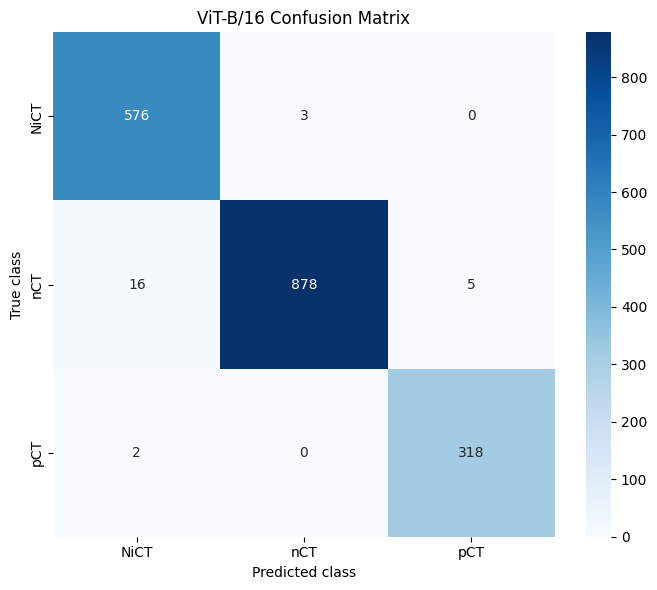


Saved results to: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched
NOTE: These are new matched-protocol results; do not substitute the previous 97.89% result unless this new run reproduces it.


In [ ]:
checkpoint = torch.load(STAGE2_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

y_true, y_pred, y_prob = [], [], []
test_loss_sum, n_test = 0.0, 0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Final test evaluation"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).long()
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(pixel_values=images).logits
            loss = weighted_loss(logits, labels)
        probs = torch.softmax(logits.float(), dim=1)
        bs = labels.size(0)
        test_loss_sum += loss.item() * bs
        n_test += bs
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(logits.argmax(dim=1).cpu().numpy())
        y_prob.extend(probs.cpu().numpy())

y_true, y_pred, y_prob = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_prob)
test_loss = test_loss_sum / n_test
accuracy = accuracy_score(y_true, y_pred)
macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
macro_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("Test samples:", n_test)
print(f"Test loss: {test_loss:.4f}")
print(f"Accuracy: {accuracy:.4%}")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall: {macro_recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(classification_report(y_true, y_pred, labels=[0,1,2], target_names=CLASS_NAMES, digits=4, zero_division=0))

metrics = {
    "Model": "ViT-B/16 (MobileNetV2-matched settings)",
    "Test_Samples": n_test, "Test_Loss": test_loss, "Accuracy": accuracy,
    "Macro_Precision": macro_precision, "Macro_Recall": macro_recall, "Macro_F1": macro_f1,
    "Best_Validation_Loss": checkpoint["best_val_loss"],
    "Best_Validation_Accuracy": checkpoint["best_val_accuracy"],
    "Best_Checkpoint_Stage": checkpoint["stage"], "Best_Checkpoint_Epoch": checkpoint["epoch"],
    "Batch_Size": BATCH_SIZE, "Seed": SEED
}
pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "ViT_B16_Matched_Test_Metrics.csv"), index=False)
pd.DataFrame(history).to_csv(os.path.join(OUT_DIR, "ViT_B16_Matched_Training_History.csv"), index=False)

cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
pd.DataFrame(cm, index=[f"True_{c}" for c in CLASS_NAMES],
             columns=[f"Pred_{c}" for c in CLASS_NAMES]).to_csv(
                 os.path.join(OUT_DIR, "ViT_B16_Matched_Confusion_Matrix.csv"))

report = classification_report(y_true, y_pred, labels=[0,1,2], target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
pd.DataFrame(report).transpose().to_csv(os.path.join(OUT_DIR, "ViT_B16_Matched_Classification_Report.csv"))

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted class"); plt.ylabel("True class"); plt.title("ViT-B/16 Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ViT_B16_Matched_Confusion_Matrix.png"), dpi=300)
plt.savefig(os.path.join(OUT_DIR, "ViT_B16_Matched_Confusion_Matrix.pdf"))
plt.show()

print("\nSaved results to:", OUT_DIR)
print("NOTE: These are new matched-protocol results; do not substitute the previous 97.89% result unless this new run reproduces it.")

In [ ]:
import os

OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

print("Folder exists:", os.path.isdir(OUT_DIR))

for root, dirs, files in os.walk(OUT_DIR):
    for file in files:
        if file.lower().endswith((".csv", ".json", ".pkl", ".pickle")):
            print(os.path.join(root, file))

Folder exists: True
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Test_Metrics.csv
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Training_History.csv
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Confusion_Matrix.csv
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Classification_Report.csv


In [ ]:
import pandas as pd
import os

history_path = os.path.join(
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched",
    "ViT_B16_Matched_Training_History.csv"
)

df = pd.read_csv(history_path)

print("Columns:", df.columns.tolist())
print("Total recorded epochs:", len(df))
display(df.head(10))
display(df.tail(10))

Columns: ['stage', 'epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'learning_rate', 'minutes']
Total recorded epochs: 100


,stage,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,minutes
0,Stage 1 - Frozen ViT,1,1.015896,0.635554,0.971968,0.644964,0.0001,45.177445
1,Stage 1 - Frozen ViT,2,0.879309,0.780293,0.883497,0.698943,0.0001,1.583999
2,Stage 1 - Frozen ViT,3,0.796711,0.810169,0.824640,0.732332,0.0001,1.623713
3,Stage 1 - Frozen ViT,4,0.741808,0.825199,0.783026,0.742348,0.0001,1.617615
4,Stage 1 - Frozen ViT,5,0.703948,0.843385,0.752785,0.710072,0.0001,1.595289
5,Stage 1 - Frozen ViT,6,0.669165,0.861755,0.726209,0.733445,0.0001,1.596840
6,Stage 1 - Frozen ViT,7,0.644274,0.877343,0.705411,0.743461,0.0001,1.595937
7,Stage 1 - Frozen ViT,8,0.621586,0.875487,0.684539,0.784085,0.0001,1.599007
8,Stage 1 - Frozen ViT,9,0.601233,0.888662,0.669429,0.787423,0.0001,1.596289
9,Stage 1 - Frozen ViT,10,0.587915,0.891446,0.656985,0.785198,0.0001,1.597066


,stage,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,minutes
90,Stage 2 - Fine-tuning last 20% of ViT blocks,31,0.306398,0.996289,0.320832,0.988870,0.00001,1.756819
91,Stage 2 - Fine-tuning last 20% of ViT blocks,32,0.306280,0.995361,0.324713,0.983862,0.00001,1.771190
92,Stage 2 - Fine-tuning last 20% of ViT blocks,33,0.306832,0.994619,0.320135,0.987757,0.00001,1.699152
93,Stage 2 - Fine-tuning last 20% of ViT blocks,34,0.305675,0.994062,0.318638,0.988870,0.00001,1.752121
94,Stage 2 - Fine-tuning last 20% of ViT blocks,35,0.303078,0.997031,0.317697,0.988314,0.00001,1.765311
95,Stage 2 - Fine-tuning last 20% of ViT blocks,36,0.302742,0.996845,0.316264,0.988314,0.00001,1.796668
96,Stage 2 - Fine-tuning last 20% of ViT blocks,37,0.303155,0.996289,0.316443,0.989983,0.00001,1.815464
97,Stage 2 - Fine-tuning last 20% of ViT blocks,38,0.303102,0.996474,0.316229,0.990540,0.00001,1.762258
98,Stage 2 - Fine-tuning last 20% of ViT blocks,39,0.303213,0.995546,0.314350,0.989427,0.00001,1.818057
99,Stage 2 - Fine-tuning last 20% of ViT blocks,40,0.300712,0.997402,0.314607,0.990540,0.00001,1.848063


Stage 1 epochs: 1–60
Stage 2 epochs: 61–100
Total epochs: 100
Saved PNG: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Accuracy_Curves.png
Saved PDF: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Accuracy_Curves.pdf


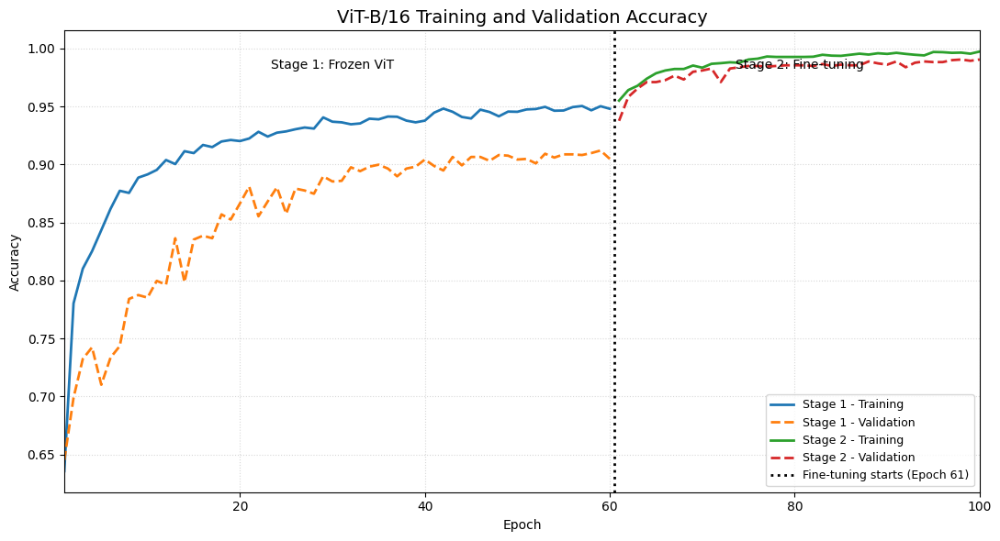

Saved PNG: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Loss_Curves.png
Saved PDF: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Loss_Curves.pdf


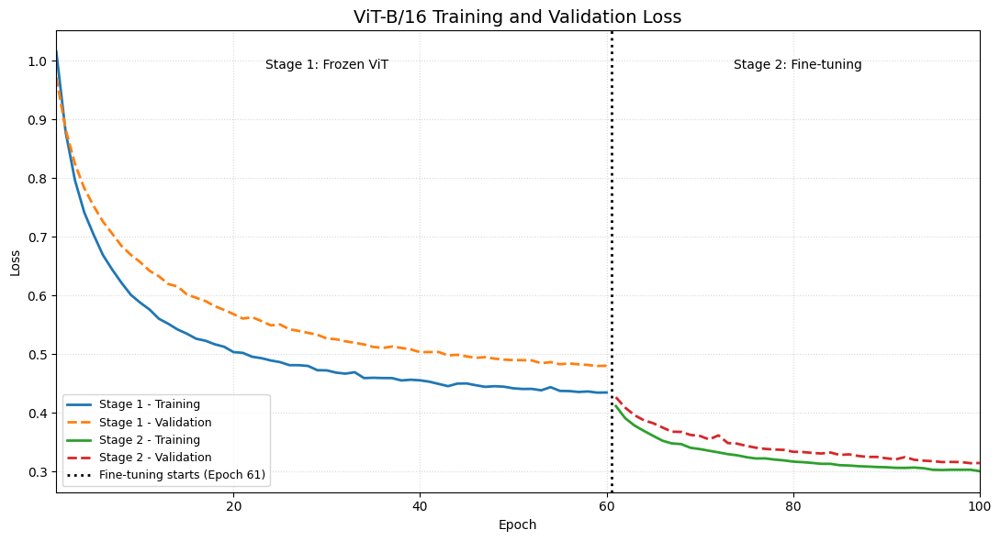


Both two-stage training curves have been generated.


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# ViT-B/16 — Two-Stage Training Curves
# Stage 1: Frozen ViT (60 epochs)
# Stage 2: Fine-tuning (40 epochs)
# =========================================================

OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

history_path = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Training_History.csv"
)

df = pd.read_csv(history_path)

# Determine the stage boundary from the saved history.
stage1_mask = df["stage"].str.contains(
    "Stage 1", case=False, na=False
)
stage2_mask = df["stage"].str.contains(
    "Stage 2", case=False, na=False
)

stage1_epochs = df.loc[stage1_mask, "epoch"]
stage2_epochs = df.loc[stage2_mask, "epoch"]

if stage1_epochs.empty or stage2_epochs.empty:
    raise ValueError(
        "Could not identify both stages in the training-history CSV."
    )

stage1_end = len(stage1_epochs)
stage2_start_global = stage1_end + 1
total_epochs = len(df)

# Global epoch numbers: Stage 1 = 1–60; Stage 2 = 61–100.
df["global_epoch"] = range(1, total_epochs + 1)

print(f"Stage 1 epochs: 1–{stage1_end}")
print(f"Stage 2 epochs: {stage2_start_global}–{total_epochs}")
print(f"Total epochs: {total_epochs}")

# Use a visible boundary between Epoch 60 and Epoch 61.
boundary_x = stage1_end + 0.5

def plot_metric(train_col, val_col, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(11, 6))

    # Stage 1
    s1 = df[stage1_mask]
    ax.plot(
        s1["global_epoch"], s1[train_col],
        label="Stage 1 - Training", linewidth=2
    )
    ax.plot(
        s1["global_epoch"], s1[val_col],
        label="Stage 1 - Validation",
        linewidth=2, linestyle="--"
    )

    # Stage 2
    s2 = df[stage2_mask]
    ax.plot(
        s2["global_epoch"], s2[train_col],
        label="Stage 2 - Training", linewidth=2
    )
    ax.plot(
        s2["global_epoch"], s2[val_col],
        label="Stage 2 - Validation",
        linewidth=2, linestyle="--"
    )

    # Stage boundary
    ax.axvline(
        x=boundary_x,
        linestyle=":",
        linewidth=2,
        color="black",
        label="Fine-tuning starts (Epoch 61)"
    )

    # Labels for the two phases
    y_min, y_max = ax.get_ylim()
    y_label = y_max - 0.06 * (y_max - y_min)

    ax.text(
        stage1_end / 2,
        y_label,
        "Stage 1: Frozen ViT",
        ha="center", va="top", fontsize=10
    )
    ax.text(
        (stage2_start_global + total_epochs) / 2,
        y_label,
        "Stage 2: Fine-tuning",
        ha="center", va="top", fontsize=10
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_xlim(1, total_epochs)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="best", fontsize=9)

    fig.tight_layout()

    png_path = os.path.join(OUT_DIR, filename + ".png")
    pdf_path = os.path.join(OUT_DIR, filename + ".pdf")

    # Save PNG first.
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    print("Saved PNG:", png_path)

    # PDF is optional; PNG remains available if PDF export fails.
    try:
        fig.savefig(pdf_path, bbox_inches="tight")
        print("Saved PDF:", pdf_path)
    except Exception as e:
        print("PDF export failed:", repr(e))

    plt.show()
    plt.close(fig)


# Figure 1: Accuracy
plot_metric(
    train_col="train_accuracy",
    val_col="val_accuracy",
    ylabel="Accuracy",
    title="ViT-B/16 Training and Validation Accuracy",
    filename="ViT_B16_Matched_Accuracy_Curves"
)

# Figure 2: Loss
plot_metric(
    train_col="train_loss",
    val_col="val_loss",
    ylabel="Loss",
    title="ViT-B/16 Training and Validation Loss",
    filename="ViT_B16_Matched_Loss_Curves"
)

print("\nBoth two-stage training curves have been generated.")


PNG saved: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Training_Curves.png
PDF saved: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Training_Curves.pdf


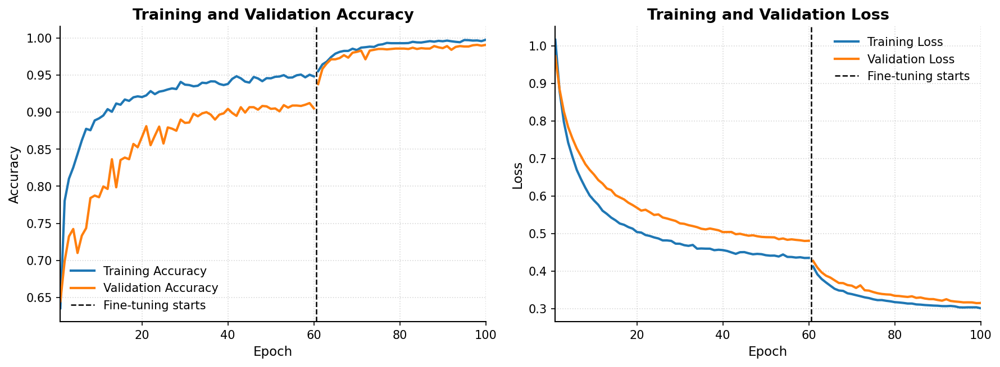

In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# Paths
# ==================================================
OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

CSV_PATH = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Training_History.csv"
)

# Load saved training history
df = pd.read_csv(CSV_PATH)
df["stage"] = df["stage"].astype(str).str.strip()

stage1 = df[df["stage"].str.contains(
    "Stage 1", case=False, na=False
)].copy()

stage2 = df[df["stage"].str.contains(
    "Stage 2", case=False, na=False
)].copy()

if stage1.empty or stage2.empty:
    raise ValueError("Stage 1 or Stage 2 was not found in the CSV.")

stage1["global_epoch"] = np.arange(1, len(stage1) + 1)
stage2["global_epoch"] = np.arange(
    len(stage1) + 1,
    len(stage1) + len(stage2) + 1
)

boundary = len(stage1) + 0.5

# Simple, consistent style
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10
})

BLUE = "tab:blue"
ORANGE = "tab:orange"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ==================================================
# Accuracy
# ==================================================
ax = axes[0]

for part in (stage1, stage2):
    ax.plot(
        part["global_epoch"], part["train_accuracy"],
        color=BLUE, linewidth=2,
        label="Training Accuracy" if part is stage1 else None
    )
    ax.plot(
        part["global_epoch"], part["val_accuracy"],
        color=ORANGE, linewidth=2,
        label="Validation Accuracy" if part is stage1 else None
    )

# Separator between the two stages
ax.axvline(
    boundary, color="black", linestyle="--",
    linewidth=1.2, label="Fine-tuning starts"
)

ax.set_title("Training and Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_xlim(1, len(df))
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=False)

# ==================================================
# Loss
# ==================================================
ax = axes[1]

for part in (stage1, stage2):
    ax.plot(
        part["global_epoch"], part["train_loss"],
        color=BLUE, linewidth=2,
        label="Training Loss" if part is stage1 else None
    )
    ax.plot(
        part["global_epoch"], part["val_loss"],
        color=ORANGE, linewidth=2,
        label="Validation Loss" if part is stage1 else None
    )

ax.axvline(
    boundary, color="black", linestyle="--",
    linewidth=1.2, label="Fine-tuning starts"
)

ax.set_title("Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_xlim(1, len(df))
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=False)

fig.tight_layout()

# Save PNG first
png_path = os.path.join(OUT_DIR, "ViT_B16_Training_Curves.png")
fig.savefig(png_path, dpi=300, bbox_inches="tight")
print("PNG saved:", png_path)

# Try PDF export
pdf_path = os.path.join(OUT_DIR, "ViT_B16_Training_Curves.pdf")
try:
    fig.savefig(pdf_path, bbox_inches="tight")
    print("PDF saved:", pdf_path)
except Exception as e:
    print("PDF export failed; PNG is saved.")
    print(repr(e))

plt.show()
plt.close(fig)


In [ ]:

import os

folders = [
    "/content/drive/MyDrive/iCTCF_CT_New/Reviewer1_Experiment2_ViT_B16",
    "/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
]

for folder in folders:
    print("\n" + "=" * 75)
    print(folder)
    print("=" * 75)

    if not os.path.exists(folder):
        print("Folder not found")
        continue

    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)

        if os.path.isfile(path):
            print(f"{name}  |  {os.path.getsize(path) / (1024**2):.2f} MB")
        else:
            print(f"[FOLDER] {name}")



/content/drive/MyDrive/iCTCF_CT_New/Reviewer1_Experiment2_ViT_B16
ViT_B16_classification_report.txt  |  0.00 MB
ViT_B16_confusion_matrix.csv  |  0.00 MB
ViT_B16_finetuned_best.keras  |  2563.96 MB
ViT_B16_stage1_best.keras  |  1518.92 MB
ViT_B16_test_results.csv  |  0.00 MB

/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched
ViT_B16_Matched_Accuracy_Curves.pdf  |  0.02 MB
ViT_B16_Matched_Accuracy_Curves.png  |  0.26 MB
ViT_B16_Matched_Classification_Report.csv  |  0.00 MB
ViT_B16_Matched_Confusion_Matrix.csv  |  0.00 MB
ViT_B16_Matched_Confusion_Matrix.pdf  |  0.01 MB
ViT_B16_Matched_Confusion_Matrix.png  |  0.09 MB
ViT_B16_Matched_Loss_Curves.pdf  |  0.02 MB
ViT_B16_Matched_Loss_Curves.png  |  0.23 MB
ViT_B16_Matched_Test_Metrics.csv  |  0.00 MB
ViT_B16_Matched_Training_History.csv  |  0.01 MB
ViT_B16_Training_Curves.pdf  |  0.02 MB
ViT_B16_Training_Curves.png  |  0.28 MB
ViT_B16_Training_Curves_Publication.pdf  |  0.03 MB
ViT_B16_Training_Curves

In [ ]:

import os
import pandas as pd

files = {
    "Test results": (
        "/content/drive/MyDrive/iCTCF_CT_New/"
        "Reviewer1_Experiment2_ViT_B16/ViT_B16_test_results.csv"
    ),
    "Matched test metrics": (
        "/content/drive/MyDrive/iCTCF_CT_New/"
        "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/"
        "ViT_B16_Matched_Test_Metrics.csv"
    ),
    "Matched classification report": (
        "/content/drive/MyDrive/iCTCF_CT_New/"
        "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/"
        "ViT_B16_Matched_Classification_Report.csv"
    ),
}

for title, path in files.items():
    print("\n" + "=" * 65)
    print(title)
    print("=" * 65)

    if os.path.exists(path):
        try:
            data = pd.read_csv(path)
            print(data.to_string(index=False))
            print("\nColumns:", list(data.columns))
        except Exception as e:
            print("Could not read CSV:", e)
    else:
        print("File not found:", path)



Test results
   Model  Seed  Test_Accuracy  Weighted_Precision  Weighted_Recall  Weighted_F1  Balanced_Accuracy
ViT-B/16    42       0.731368            0.746289         0.731368     0.695552           0.611662

Columns: ['Model', 'Seed', 'Test_Accuracy', 'Weighted_Precision', 'Weighted_Recall', 'Weighted_F1', 'Balanced_Accuracy']

Matched test metrics
                                  Model  Test_Samples  Test_Loss  Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Best_Validation_Loss  Best_Validation_Accuracy                        Best_Checkpoint_Stage  Best_Checkpoint_Epoch  Batch_Size  Seed
ViT-B/16 (MobileNetV2-matched settings)          1798    0.32196  0.985539         0.983604      0.988403  0.985909               0.31435                  0.989427 Stage 2 - Fine-tuning last 20% of ViT blocks                     39          32    42

Columns: ['Model', 'Test_Samples', 'Test_Loss', 'Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Best_Validation_Loss', 'Best_Valida

In [ ]:

import os

ROOT = "/content/drive/MyDrive/iCTCF_CT_New"

image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for folder_name in ["train", "val", "validation", "test"]:
    path = os.path.join(ROOT, folder_name)

    if not os.path.isdir(path):
        continue

    print(f"\n{folder_name.upper()}: {path}")

    for cls in sorted(os.listdir(path)):
        cls_path = os.path.join(path, cls)

        if os.path.isdir(cls_path):
            count = sum(
                1 for f in os.listdir(cls_path)
                if f.lower().endswith(image_exts)
            )
            print(f"  {cls}: {count} images")



TRAIN: /content/drive/MyDrive/iCTCF_CT_New/train
  NiCT: 1736 images
  nCT: 2695 images
  pCT: 958 images

VALIDATION: /content/drive/MyDrive/iCTCF_CT_New/validation
  NiCT: 579 images
  nCT: 899 images
  pCT: 319 images

TEST: /content/drive/MyDrive/iCTCF_CT_New/test
  NiCT: 579 images
  nCT: 899 images
  pCT: 320 images


In [ ]:

import os
import pandas as pd

OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

MODEL_PATH = os.path.join(
    OUT_DIR, "final_best_finetuned_ViT_B16.pt"
)

METRICS_PATH = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Test_Metrics.csv"
)

print("Model exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    print("Model size (MB):", round(
        os.path.getsize(MODEL_PATH) / (1024**2), 2
    ))

metrics = pd.read_csv(METRICS_PATH)
print("\nSaved test metrics:")
print(metrics.to_string(index=False))


Model exists: True
Model size (MB): 327.38

Saved test metrics:
                                  Model  Test_Samples  Test_Loss  Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Best_Validation_Loss  Best_Validation_Accuracy                        Best_Checkpoint_Stage  Best_Checkpoint_Epoch  Batch_Size  Seed
ViT-B/16 (MobileNetV2-matched settings)          1798    0.32196  0.985539         0.983604      0.988403  0.985909               0.31435                  0.989427 Stage 2 - Fine-tuning last 20% of ViT blocks                     39          32    42


In [ ]:

import os
import torch

MODEL_PATH = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/"
    "final_best_finetuned_ViT_B16.pt"
)

print("PyTorch version:", torch.__version__)
print("Checkpoint exists:", os.path.exists(MODEL_PATH))

# Load safely for inspection; do not load arbitrary pickled objects.
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

print("\nCheckpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys())[:40])

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n[{key}] nested dictionary; keys:",
                  list(value.keys())[:15])

            tensor_items = [
                (k, v) for k, v in value.items()
                if isinstance(v, torch.Tensor)
            ]
            print("Number of tensors:", len(tensor_items))

            for name, tensor in tensor_items[:12]:
                print(f"  {name}: {tuple(tensor.shape)}")

        elif isinstance(value, torch.Tensor):
            print(f"{key}: tensor shape={tuple(value.shape)}")

        else:
            print(f"{key}: {type(value).__name__}")
else:
    print("Checkpoint is not a dictionary.")


PyTorch version: 2.11.0+cu130
Checkpoint exists: True

Checkpoint type: dict
Top-level keys: ['model_state_dict', 'best_val_loss', 'best_val_accuracy', 'stage', 'epoch', 'model_id', 'class_names', 'seed']

[model_state_dict] nested dictionary; keys: ['vit.embeddings.cls_token', 'vit.embeddings.position_embeddings', 'vit.embeddings.patch_embeddings.projection.weight', 'vit.embeddings.patch_embeddings.projection.bias', 'vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight']
Number of tensors: 200
  vit.embeddings.cls_token: (1, 1, 768)
  vit.embeddings.position_embeddings: (1, 197, 768)
  vit.embeddings.patch_embeddings.p

In [ ]:

import torch

checkpoint = torch.load(
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/"
    "final_best_finetuned_ViT_B16.pt",
    map_location="cpu",
    weights_only=True
)

print("Model ID:", checkpoint.get("model_id"))
print("Class names:", checkpoint.get("class_names"))
print("Stage:", checkpoint.get("stage"))
print("Best epoch:", checkpoint.get("epoch"))
print("Seed:", checkpoint.get("seed"))

state = checkpoint["model_state_dict"]
print("\nLast 30 parameter names and shapes:")
for name, tensor in list(state.items())[-30:]:
    print(name, tuple(tensor.shape))


Model ID: google/vit-base-patch16-224-in21k
Class names: ['NiCT', 'nCT', 'pCT']
Stage: Stage 2 - Fine-tuning last 20% of ViT blocks
Best epoch: 39
Seed: 42

Last 30 parameter names and shapes:
vit.layers.10.attention.o_proj.weight (768, 768)
vit.layers.10.attention.o_proj.bias (768,)
vit.layers.10.layernorm_before.weight (768,)
vit.layers.10.layernorm_before.bias (768,)
vit.layers.10.layernorm_after.weight (768,)
vit.layers.10.layernorm_after.bias (768,)
vit.layers.10.mlp.fc1.weight (3072, 768)
vit.layers.10.mlp.fc1.bias (3072,)
vit.layers.10.mlp.fc2.weight (768, 3072)
vit.layers.10.mlp.fc2.bias (768,)
vit.layers.11.attention.q_proj.weight (768, 768)
vit.layers.11.attention.q_proj.bias (768,)
vit.layers.11.attention.k_proj.weight (768, 768)
vit.layers.11.attention.k_proj.bias (768,)
vit.layers.11.attention.v_proj.weight (768, 768)
vit.layers.11.attention.v_proj.bias (768,)
vit.layers.11.attention.o_proj.weight (768, 768)
vit.layers.11.attention.o_proj.bias (768,)
vit.layers.11.layernor

Device: cuda


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ImageFolder mapping: {'NiCT': 0, 'nCT': 1, 'pCT': 2}
Test image count: 1798
Processed batches: 20
Processed batches: 40
Processed batches: 60
Processed batches: 80
Processed batches: 100

Re-evaluated accuracy: 98.553949%
Expected saved accuracy: 98.553900%
Correct predictions: 1772
Total test images: 1798
Saved probabilities: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_Test_Probabilities.npz


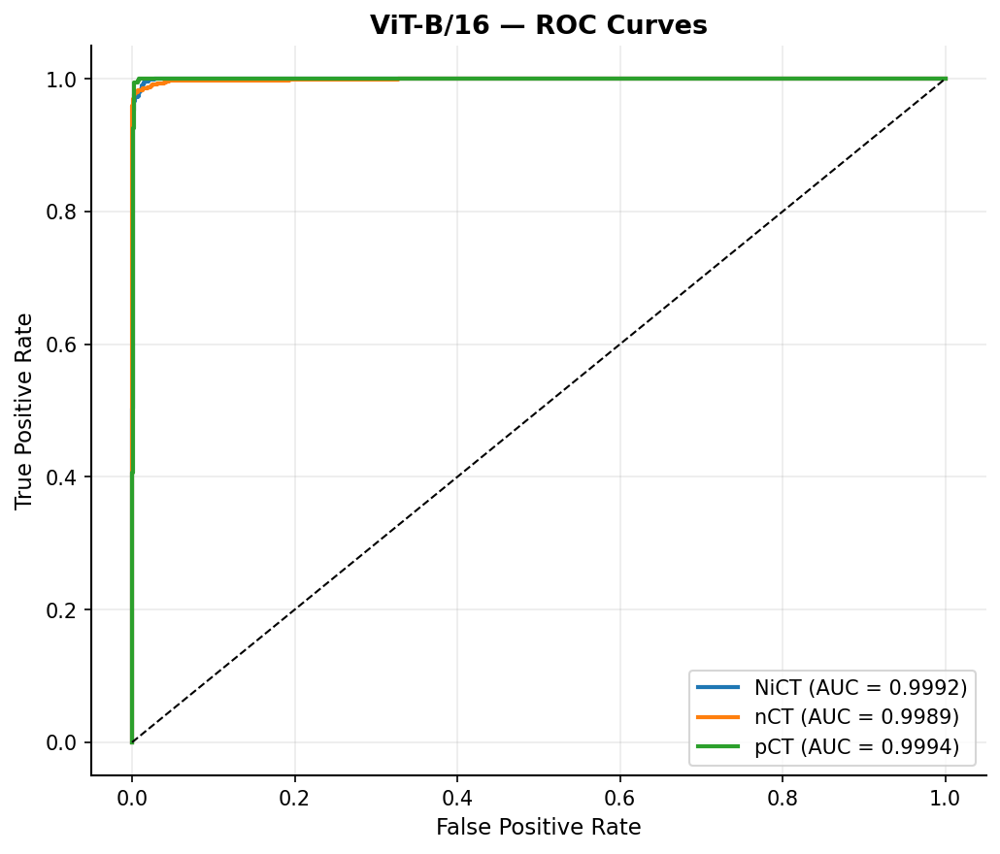

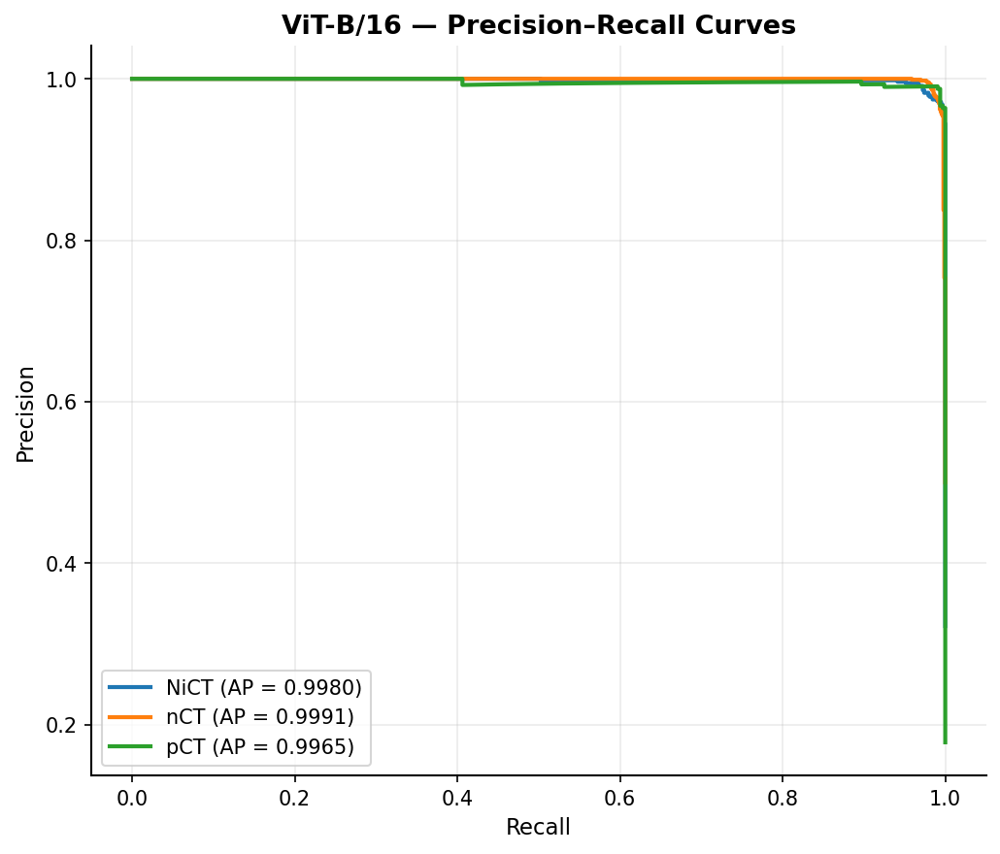


Saved files:
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_ROC.png
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_ROC.pdf
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_PR.png
/content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_PR.pdf


In [ ]:

import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
from transformers import (
    ViTForImageClassification,
    AutoImageProcessor
)
from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# ============================================================
# PATHS AND SETTINGS
# ============================================================
BASE_DIR = "/content/drive/MyDrive/iCTCF_CT_New"
TEST_DIR = os.path.join(BASE_DIR, "test")

OUT_DIR = os.path.join(
    BASE_DIR,
    "Publication_PDFs_All_Models",
    "ViT_B16_MobileNetMatched"
)

MODEL_PATH = os.path.join(
    OUT_DIR, "final_best_finetuned_ViT_B16.pt"
)

CLASS_NAMES = ["NiCT", "nCT", "pCT"]
EXPECTED_ACCURACY = 0.985539
BATCH_SIZE = 16

os.makedirs(OUT_DIR, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

# ============================================================
# LOAD SAVED CHECKPOINT
# ============================================================
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["class_names"] == CLASS_NAMES, (
    f"Unexpected class order: {checkpoint['class_names']}"
)

processor = AutoImageProcessor.from_pretrained(
    checkpoint["model_id"]
)

model = ViTForImageClassification.from_pretrained(
    checkpoint["model_id"],
    num_labels=len(CLASS_NAMES)
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device)
model.eval()

# ============================================================
# TEST DATA
# ImageFolder class indices must match the checkpoint order.
# ============================================================
base_dataset = ImageFolder(TEST_DIR)

print("ImageFolder mapping:", base_dataset.class_to_idx)
print("Test image count:", len(base_dataset))

expected_mapping = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

if base_dataset.class_to_idx != expected_mapping:
    raise ValueError(
        "Class mapping differs from checkpoint order. "
        f"Expected {expected_mapping}, "
        f"found {base_dataset.class_to_idx}. "
        "Stop here; do not calculate curves until corrected."
    )

class ProcessorDataset(Dataset):
    def __init__(self, image_folder):
        self.dataset = image_folder

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        return image.convert("RGB"), label

test_dataset = ProcessorDataset(base_dataset)

def collate_images(batch):
    images, labels = zip(*batch)
    inputs = processor(
        images=list(images),
        return_tensors="pt"
    )
    inputs["labels_for_metrics"] = torch.tensor(
        labels, dtype=torch.long
    )
    return inputs

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_images
)

# ============================================================
# INFERENCE ONLY — NO TRAINING
# ============================================================
all_labels = []
all_probs = []

with torch.inference_mode():
    for batch_idx, batch in enumerate(test_loader, start=1):
        labels = batch.pop("labels_for_metrics")
        pixel_values = batch["pixel_values"].to(device)

        logits = model(pixel_values=pixel_values).logits
        probabilities = torch.softmax(logits, dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_probs.append(probabilities.cpu().numpy())

        if batch_idx % 20 == 0:
            print(f"Processed batches: {batch_idx}")

y_true = np.asarray(all_labels)
y_prob = np.concatenate(all_probs, axis=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)

print("\nRe-evaluated accuracy:", f"{accuracy:.6%}")
print("Expected saved accuracy:", f"{EXPECTED_ACCURACY:.6%}")
print("Correct predictions:", int((y_true == y_pred).sum()))
print("Total test images:", len(y_true))

# Require an exact match in correct-prediction count.
expected_correct = round(EXPECTED_ACCURACY * len(y_true))
actual_correct = int((y_true == y_pred).sum())

if len(y_true) != 1798 or actual_correct != expected_correct:
    raise RuntimeError(
        "\nSTOP: Re-evaluated predictions do not reproduce "
        "the saved test accuracy. No ROC/PR plots were saved. "
        "The original image preprocessing/evaluation code is "
        "needed to reproduce the experiment faithfully."
    )

# ============================================================
# SAVE PER-IMAGE PROBABILITIES
# ============================================================
prob_path = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Test_Probabilities.npz"
)

np.savez(
    prob_path,
    y_true=y_true,
    y_pred=y_pred,
    y_prob=y_prob,
    class_names=np.asarray(CLASS_NAMES)
)
print("Saved probabilities:", prob_path)

# One-vs-rest binary labels for each class
y_binary = label_binarize(
    y_true, classes=np.arange(len(CLASS_NAMES))
)

# ============================================================
# ROC CURVES
# ============================================================
plt.figure(figsize=(7, 6))

for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_binary[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr, tpr, linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ViT-B/16 — ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

roc_png = os.path.join(OUT_DIR, "ViT_B16_Matched_ROC.png")
roc_pdf = os.path.join(OUT_DIR, "ViT_B16_Matched_ROC.pdf")
plt.savefig(roc_png, dpi=300, bbox_inches="tight")
plt.savefig(roc_pdf, bbox_inches="tight")
plt.show()
plt.close()

# ============================================================
# PRECISION–RECALL CURVES
# ============================================================
plt.figure(figsize=(7, 6))

for i, class_name in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(
        y_binary[:, i], y_prob[:, i]
    )
    ap = average_precision_score(
        y_binary[:, i], y_prob[:, i]
    )
    plt.plot(
        recall, precision, linewidth=2,
        label=f"{class_name} (AP = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ViT-B/16 — Precision–Recall Curves")
plt.legend(loc="lower left")
plt.grid(alpha=0.25)
plt.tight_layout()

pr_png = os.path.join(OUT_DIR, "ViT_B16_Matched_PR.png")
pr_pdf = os.path.join(OUT_DIR, "ViT_B16_Matched_PR.pdf")
plt.savefig(pr_png, dpi=300, bbox_inches="tight")
plt.savefig(pr_pdf, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved files:")
for path in [roc_png, roc_pdf, pr_png, pr_pdf]:
    print(path)


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

data = np.load(
    os.path.join(OUT_DIR, "ViT_B16_Matched_Test_Probabilities.npz")
)

y_true = data["y_true"]
y_prob = data["y_prob"]
class_names = data["class_names"].tolist()

rows = []

for i, name in enumerate(class_names):
    y_binary = (y_true == i).astype(int)

    rows.append({
        "Class": name,
        "ROC_AUC": roc_auc_score(y_binary, y_prob[:, i]),
        "Average_Precision_AP": average_precision_score(
            y_binary, y_prob[:, i]
        ),
        "Support": int(y_binary.sum())
    })

results = pd.DataFrame(rows)

# Macro averages: each class contributes equally
results.loc[len(results)] = {
    "Class": "Macro Average",
    "ROC_AUC": results["ROC_AUC"].mean(),
    "Average_Precision_AP": results["Average_Precision_AP"].mean(),
    "Support": len(y_true)
}

csv_path = os.path.join(
    OUT_DIR, "ViT_B16_Matched_ROC_PR_Metrics.csv"
)
results.to_csv(csv_path, index=False)

print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nSaved:", csv_path)


        Class  ROC_AUC  Average_Precision_AP  Support
         NiCT   0.9992                0.9980      579
          nCT   0.9989                0.9991      899
          pCT   0.9994                0.9965      320
Macro Average   0.9992                0.9979     1798

Saved: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Matched_ROC_PR_Metrics.csv


In [ ]:
import os
import numpy as np
import pandas as pd

OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

required_files = [
    "final_best_finetuned_ViT_B16.pt",
    "ViT_B16_Matched_Test_Metrics.csv",
    "ViT_B16_Matched_Test_Probabilities.npz",
    "ViT_B16_Matched_ROC_PR_Metrics.csv",
    "ViT_B16_Matched_ROC.png",
    "ViT_B16_Matched_ROC.pdf",
    "ViT_B16_Matched_PR.png",
    "ViT_B16_Matched_PR.pdf",
]

for filename in required_files:
    path = os.path.join(OUT_DIR, filename)
    print(
        ("OK      " if os.path.exists(path) else "MISSING "),
        filename
    )

data = np.load(
    os.path.join(
        OUT_DIR,
        "ViT_B16_Matched_Test_Probabilities.npz"
    )
)

print("\nProbability array shape:", data["y_prob"].shape)
print("Number of test labels:", len(data["y_true"]))
print("Class order:", data["class_names"].tolist())

OK       final_best_finetuned_ViT_B16.pt
OK       ViT_B16_Matched_Test_Metrics.csv
OK       ViT_B16_Matched_Test_Probabilities.npz
OK       ViT_B16_Matched_ROC_PR_Metrics.csv
OK       ViT_B16_Matched_ROC.png
OK       ViT_B16_Matched_ROC.pdf
OK       ViT_B16_Matched_PR.png
OK       ViT_B16_Matched_PR.pdf

Probability array shape: (1798, 3)
Number of test labels: 1798
Class order: ['NiCT', 'nCT', 'pCT']


ViT-B/16 ATTENTION ROLLOUT
Device: cuda
ImageFolder classes: ['NiCT', 'nCT', 'pCT']
Test images: 1798
Probability shape: (1798, 3)
Class order: ['NiCT', 'nCT', 'pCT']

Selected image: /content/drive/MyDrive/iCTCF_CT_New/test/NiCT/NiCT5473.jpg
True class: NiCT
Predicted class: NiCT
Prediction confidence: 96.7537%

Checkpoint loaded successfully.
Checkpoint epoch: 39
Checkpoint seed: 42
Checkpoint stage: Stage 2 - Fine-tuning last 20% of ViT blocks
Attention implementation: eager

Number of attention layers: 12
First layer attention shape: (1, 12, 197, 197)
Patch grid: 14 x 14


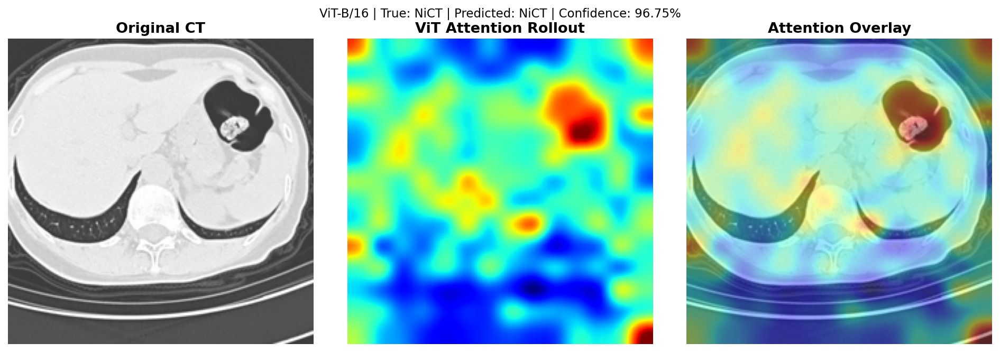


ATTENTION ROLLOUT COMPLETED
PNG saved: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout_Sample.png
PDF saved: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout_Sample.pdf


In [ ]:

# ============================================================
# ViT-B/16 Attention Rollout — Complete Corrected Code
# Uses the matched experiment checkpoint and test set
# No training is performed
# ============================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.datasets import ImageFolder
from transformers import AutoImageProcessor, ViTForImageClassification

# ============================================================
# 1. Paths and configuration
# ============================================================

OUT_DIR = (
    "/content/drive/MyDrive/iCTCF_CT_New/"
    "Publication_PDFs_All_Models/ViT_B16_MobileNetMatched"
)

TEST_DIR = "/content/drive/MyDrive/iCTCF_CT_New/test"

CHECKPOINT_PATH = os.path.join(
    OUT_DIR, "final_best_finetuned_ViT_B16.pt"
)

PROB_PATH = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Test_Probabilities.npz"
)

MODEL_ID = "google/vit-base-patch16-224-in21k"
CLASS_NAMES = ["NiCT", "nCT", "pCT"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("ViT-B/16 ATTENTION ROLLOUT")
print("=" * 65)
print("Device:", DEVICE)

# Verify that required files exist
for path in [CHECKPOINT_PATH, PROB_PATH, TEST_DIR]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required path not found: {path}")

# ============================================================
# 2. Load the same test set and saved predictions
# ============================================================

dataset = ImageFolder(TEST_DIR)

print("ImageFolder classes:", dataset.classes)

if dataset.classes != CLASS_NAMES:
    raise ValueError(
        f"Unexpected class order: {dataset.classes}; "
        f"expected {CLASS_NAMES}"
    )

saved = np.load(PROB_PATH)

y_true = saved["y_true"]
y_prob = saved["y_prob"]
saved_class_names = saved["class_names"].tolist()
y_pred = np.argmax(y_prob, axis=1)

if saved_class_names != CLASS_NAMES:
    raise ValueError(
        f"Saved probability class order is incorrect: "
        f"{saved_class_names}"
    )

if len(dataset.samples) != len(y_true):
    raise ValueError(
        f"Test count mismatch: {len(dataset.samples)} images "
        f"versus {len(y_true)} saved predictions."
    )

print("Test images:", len(dataset.samples))
print("Probability shape:", y_prob.shape)
print("Class order:", CLASS_NAMES)

# ============================================================
# 3. Select one high-confidence, correctly classified NiCT
# ============================================================

candidates = np.where(
    (y_true == 0) &
    (y_pred == 0) &
    (y_prob[:, 0] >= 0.90)
)[0]

if len(candidates) > 0:
    idx = candidates[
        np.argmax(y_prob[candidates, 0])
    ]
else:
    # Fallback: highest-confidence correct prediction
    candidates = np.where(y_true == y_pred)[0]

    if len(candidates) == 0:
        raise RuntimeError(
            "No correctly classified image was found."
        )

    idx = candidates[
        np.argmax(y_prob[candidates].max(axis=1))
    ]

image_path, folder_label = dataset.samples[idx]

true_idx = int(y_true[idx])
pred_idx = int(y_pred[idx])
confidence = float(y_prob[idx, pred_idx])

print("\nSelected image:", image_path)
print("True class:", CLASS_NAMES[true_idx])
print("Predicted class:", CLASS_NAMES[pred_idx])
print(f"Prediction confidence: {confidence:.4%}")

# ============================================================
# 4. Load processor and model configuration
# ============================================================

processor = AutoImageProcessor.from_pretrained(MODEL_ID)

# IMPORTANT FIX:
# Set num_labels in the configuration, then instantiate the model
# directly. This avoids the earlier from_pretrained(num_labels=3)
# constructor error.
config_model = (
    ViTForImageClassification.config_class.from_pretrained(
        MODEL_ID,
        num_labels=3
    )
)

# Request eager attention to obtain attention matrices
config_model._attn_implementation = "eager"

model = ViTForImageClassification(config_model)

# ============================================================
# 5. Load the exact fine-tuned checkpoint
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise KeyError(
        "The checkpoint does not contain 'model_state_dict'."
    )

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.to(DEVICE)
model.eval()

print("\nCheckpoint loaded successfully.")
print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Checkpoint seed:", checkpoint.get("seed"))
print("Checkpoint stage:", checkpoint.get("stage"))
print(
    "Attention implementation:",
    config_model._attn_implementation
)

# ============================================================
# 6. Load selected image and extract attention
# ============================================================

original = Image.open(image_path).convert("RGB")

inputs = processor(
    images=original,
    return_tensors="pt"
)

pixel_values = inputs["pixel_values"].to(DEVICE)

with torch.no_grad():
    outputs = model(
        pixel_values=pixel_values,
        output_attentions=True,
        return_dict=True
    )

attentions = outputs.attentions

if attentions is None:
    raise RuntimeError(
        "No attention matrices were returned. "
        "Please share the Transformers version and error output."
    )

if any(attention is None for attention in attentions):
    raise RuntimeError(
        "At least one attention layer returned None."
    )

print("\nNumber of attention layers:", len(attentions))
print(
    "First layer attention shape:",
    tuple(attentions[0].shape)
)

# ============================================================
# 7. Calculate Attention Rollout
# ============================================================

# Attention tensor shape:
# (batch_size, number_of_heads, number_of_tokens, number_of_tokens)

num_tokens = attentions[0].shape[-1]

joint_attention = torch.eye(
    num_tokens,
    device=DEVICE
).unsqueeze(0)

for attention in attentions:

    # Average attention across heads
    attention_heads = attention.mean(dim=1)

    # Include residual connections
    identity = torch.eye(
        num_tokens,
        device=DEVICE
    ).unsqueeze(0)

    attention_residual = attention_heads + identity

    # Normalize each row
    attention_residual = (
        attention_residual /
        attention_residual.sum(
            dim=-1,
            keepdim=True
        ).clamp(min=1e-12)
    )

    # Compose attention across layers
    joint_attention = torch.bmm(
        attention_residual,
        joint_attention
    )

# CLS token (index 0) to image patch tokens
cls_attention = joint_attention[0, 0, 1:]

num_patches = cls_attention.numel()
grid_size = int(np.sqrt(num_patches))

if grid_size * grid_size != num_patches:
    raise RuntimeError(
        f"Patch count {num_patches} does not form a square grid."
    )

attention_map = (
    cls_attention
    .reshape(grid_size, grid_size)
    .detach()
    .float()
    .cpu()
    .numpy()
)

# Normalize attention map
attention_map = attention_map - attention_map.min()

if attention_map.max() > 0:
    attention_map = attention_map / attention_map.max()

print("Patch grid:", f"{grid_size} x {grid_size}")

# ============================================================
# 8. Resize attention map to 224 x 224
# ============================================================

display_image = original.resize(
    (224, 224),
    Image.Resampling.BICUBIC
)

heatmap_image = Image.fromarray(
    np.uint8(
        np.clip(attention_map, 0, 1) * 255
    )
).resize(
    (224, 224),
    Image.Resampling.BICUBIC
)

heatmap = np.asarray(
    heatmap_image,
    dtype=np.float32
) / 255.0

base_image = np.asarray(display_image)

# ============================================================
# 9. Visualize original, attention, and overlay
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4.5)
)

axes[0].imshow(base_image)
axes[0].set_title("Original CT")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("ViT Attention Rollout")

axes[2].imshow(base_image)
axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.40,
    vmin=0,
    vmax=1
)
axes[2].set_title("Attention Overlay")

for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"ViT-B/16 | True: {CLASS_NAMES[true_idx]} | "
    f"Predicted: {CLASS_NAMES[pred_idx]} | "
    f"Confidence: {confidence:.2%}",
    fontsize=11
)

fig.tight_layout()

# ============================================================
# 10. Save PNG and PDF
# ============================================================

png_path = os.path.join(
    OUT_DIR,
    "ViT_B16_Attention_Rollout_Sample.png"
)

pdf_path = os.path.join(
    OUT_DIR,
    "ViT_B16_Attention_Rollout_Sample.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 65)
print("ATTENTION ROLLOUT COMPLETED")
print("=" * 65)
print("PNG saved:", png_path)
print("PDF saved:", pdf_path)


ViT-B/16 — 30-CASE ATTENTION ROLLOUT
Device: cuda
Output folder: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout_30_Cases
Test images: 1798
Probability shape: (1798, 3)
Classes: ['NiCT', 'nCT', 'pCT']

Case availability check:
True_Class                  Category  Available  Required
      NiCT   High-confidence correct        497         3
      NiCT Medium-confidence correct         70         3
      NiCT    Low-confidence correct          9         2
      NiCT             Misclassified          3         2
       pCT   High-confidence correct        212         3
       pCT Medium-confidence correct         92         3
       pCT    Low-confidence correct         14         2
       pCT             Misclassified          2         2
       nCT   High-confidence correct        788         3
       nCT Medium-confidence correct         77         3
       nCT    Low-confidence correct         13         2
       nCT

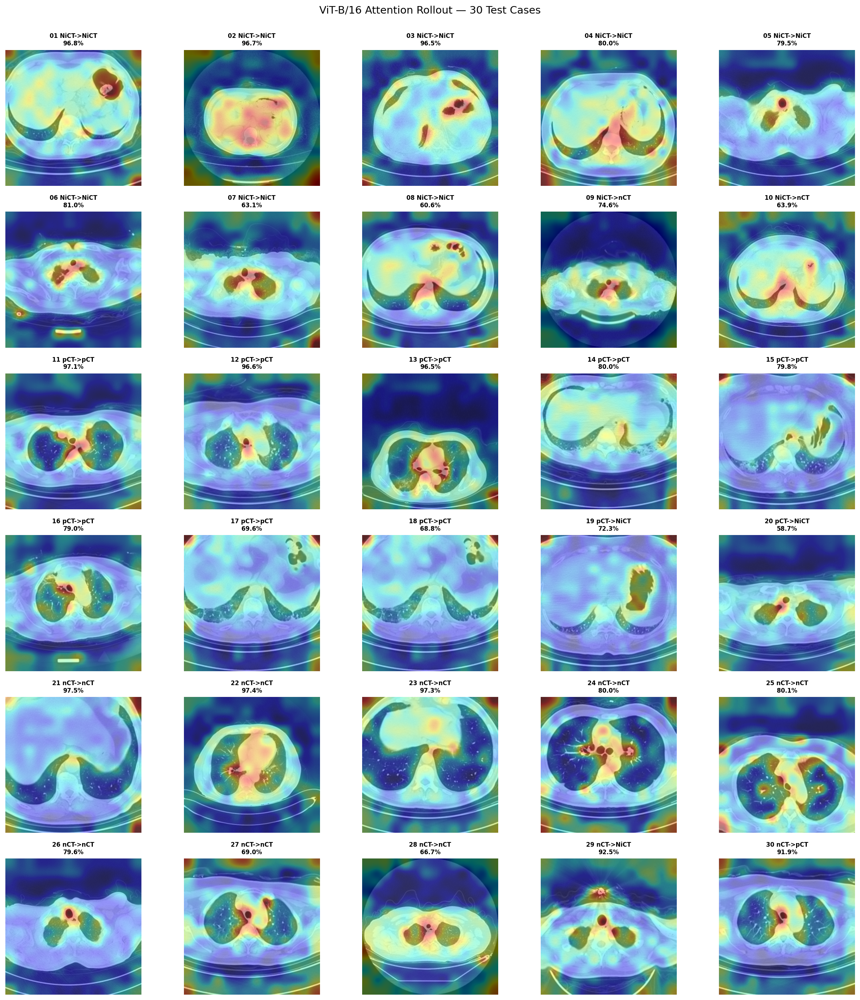


30-CASE ATTENTION ROLLOUT COMPLETED
Total cases: 30

Cases per true class:
True_Class
NiCT    10
pCT     10
nCT     10

Cases per selection category:
Selection_Category
High-confidence correct      9
Medium-confidence correct    9
Low-confidence correct       6
Misclassified                6

Saved CSV: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout_30_Cases/ViT_B16_Attention_Rollout_30_Cases.csv
Contact sheet PNG: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout_30_Cases/ViT_B16_Attention_Rollout_30_Cases_ContactSheet.png
Contact sheet PDF: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout_30_Cases/ViT_B16_Attention_Rollout_30_Cases_ContactSheet.pdf
Individual figures folder: /content/drive/MyDrive/iCTCF_CT_New/Publication_PDFs_All_Models/ViT_B16_MobileNetMatched/ViT_B16_Attention_Rollout

In [ ]:

# ============================================================
# ViT-B/16 — Attention Rollout for 30 Test Cases
# Same case-selection protocol as the MobileNetV2 visualization
# No retraining
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.datasets import ImageFolder
from transformers import AutoImageProcessor, ViTForImageClassification

# ============================================================
# 1. Paths and settings
# ============================================================

BASE_DIR = "/content/drive/MyDrive/iCTCF_CT_New"

OUT_DIR = os.path.join(
    BASE_DIR,
    "Publication_PDFs_All_Models",
    "ViT_B16_MobileNetMatched"
)

CHECKPOINT_PATH = os.path.join(
    OUT_DIR, "final_best_finetuned_ViT_B16.pt"
)

PROB_PATH = os.path.join(
    OUT_DIR, "ViT_B16_Matched_Test_Probabilities.npz"
)

TEST_DIR = os.path.join(BASE_DIR, "test")

CASE_DIR = os.path.join(
    OUT_DIR, "ViT_B16_Attention_Rollout_30_Cases"
)

os.makedirs(CASE_DIR, exist_ok=True)

MODEL_ID = "google/vit-base-patch16-224-in21k"

# Internal ImageFolder/probability order
CLASS_NAMES = ["NiCT", "nCT", "pCT"]

# Preferred figure order to match the manuscript figures
DISPLAY_CLASSES = ["NiCT", "pCT", "nCT"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("ViT-B/16 — 30-CASE ATTENTION ROLLOUT")
print("=" * 70)
print("Device:", DEVICE)
print("Output folder:", CASE_DIR)

for path in [CHECKPOINT_PATH, PROB_PATH, TEST_DIR]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing required path: {path}")

# ============================================================
# 2. Load test images and verified predictions
# ============================================================

dataset = ImageFolder(TEST_DIR)

if dataset.classes != CLASS_NAMES:
    raise ValueError(
        f"Unexpected ImageFolder class order: {dataset.classes}"
    )

saved = np.load(PROB_PATH)

y_true = saved["y_true"].astype(int)
y_prob = saved["y_prob"]
saved_classes = saved["class_names"].tolist()
y_pred = np.argmax(y_prob, axis=1)

if saved_classes != CLASS_NAMES:
    raise ValueError(
        f"Unexpected saved probability class order: {saved_classes}"
    )

if len(dataset.samples) != len(y_true):
    raise ValueError(
        "Test image count does not match the saved predictions."
    )

# Confidence of the predicted class for every image
pred_confidence = y_prob[
    np.arange(len(y_pred)), y_pred
]

# Confidence assigned to the true class
true_class_confidence = y_prob[
    np.arange(len(y_true)), y_true
]

print("Test images:", len(dataset.samples))
print("Probability shape:", y_prob.shape)
print("Classes:", CLASS_NAMES)

# ============================================================
# 3. Select 10 cases per class
#    3 high + 3 medium + 2 low + 2 misclassified
# ============================================================

selected_cases = []
selection_report = []

for class_name in DISPLAY_CLASSES:

    class_idx = CLASS_NAMES.index(class_name)

    # Images belonging to this true class
    true_class_mask = (y_true == class_idx)

    # Correctly classified examples of this class
    correct_mask = true_class_mask & (y_pred == y_true)

    # Misclassified examples whose TRUE class is this class
    error_mask = true_class_mask & (y_pred != y_true)

    # Confidence for correct predictions is probability of true class
    high_candidates = np.where(
        correct_mask & (true_class_confidence >= 0.90)
    )[0]

    medium_candidates = np.where(
        correct_mask &
        (true_class_confidence >= 0.70) &
        (true_class_confidence < 0.90)
    )[0]

    low_candidates = np.where(
        correct_mask & (true_class_confidence < 0.70)
    )[0]

    error_candidates = np.where(error_mask)[0]

    # Choose representative examples from each category.
    # High: highest confidence first.
    high_candidates = high_candidates[
        np.argsort(-true_class_confidence[high_candidates])
    ]

    # Medium: confidence closest to 0.80 first.
    medium_candidates = medium_candidates[
        np.argsort(
            np.abs(true_class_confidence[medium_candidates] - 0.80)
        )
    ]

    # Low: choose correct cases closest to the 0.70 boundary first.
    low_candidates = low_candidates[
        np.argsort(-true_class_confidence[low_candidates])
    ]

    # Errors: show the most confident incorrect predictions first.
    error_candidates = error_candidates[
        np.argsort(-pred_confidence[error_candidates])
    ]

    requested = [
        ("High-confidence correct", high_candidates, 3),
        ("Medium-confidence correct", medium_candidates, 3),
        ("Low-confidence correct", low_candidates, 2),
        ("Misclassified", error_candidates, 2),
    ]

    for category, candidates, required in requested:
        selection_report.append({
            "True_Class": class_name,
            "Category": category,
            "Available": len(candidates),
            "Required": required
        })

        if len(candidates) < required:
            continue

        for idx in candidates[:required]:
            selected_cases.append({
                "index": int(idx),
                "true_class": class_name,
                "predicted_class": CLASS_NAMES[int(y_pred[idx])],
                "confidence": float(pred_confidence[idx]),
                "true_class_confidence": float(
                    true_class_confidence[idx]
                ),
                "category": category
            })

report_df = pd.DataFrame(selection_report)
print("\nCase availability check:")
print(report_df.to_string(index=False))

if len(selected_cases) != 30:
    # Do not silently substitute cases or change the thresholds.
    raise RuntimeError(
        "\nThe requested 30 cases could not be selected using the "
        "specified confidence bins. Read the availability table above "
        "and send it to me so we can adapt the selection transparently."
    )

# Verify exactly 10 cases per true class
selected_df = pd.DataFrame(selected_cases)

print("\nSelected category counts:")
print(
    selected_df.groupby(["true_class", "category"])
    .size()
    .to_string()
)

assert len(selected_df) == 30

# ============================================================
# 4. Load ViT processor and model
# ============================================================

processor = AutoImageProcessor.from_pretrained(MODEL_ID)

config_model = (
    ViTForImageClassification.config_class.from_pretrained(
        MODEL_ID,
        num_labels=3
    )
)

# Force eager attention so attention matrices are returned.
config_model._attn_implementation = "eager"

# Instantiate directly to avoid the previous num_labels error.
model = ViTForImageClassification(config_model)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.to(DEVICE)
model.eval()

print("\nFine-tuned checkpoint loaded.")
print("Epoch:", checkpoint.get("epoch"))
print("Seed:", checkpoint.get("seed"))
print("Stage:", checkpoint.get("stage"))

# ============================================================
# 5. Helper: calculate Attention Rollout
# ============================================================

def calculate_attention_rollout(attentions):

    num_tokens = attentions[0].shape[-1]

    joint_attention = torch.eye(
        num_tokens,
        device=attentions[0].device
    ).unsqueeze(0)

    for attention in attentions:

        # Average attention across heads
        attention_heads = attention.mean(dim=1)

        # Add residual connection
        identity = torch.eye(
            num_tokens,
            device=attention.device
        ).unsqueeze(0)

        attention_residual = attention_heads + identity

        # Normalize rows
        attention_residual = (
            attention_residual /
            attention_residual.sum(
                dim=-1,
                keepdim=True
            ).clamp(min=1e-12)
        )

        # Compose attention from layer to layer
        joint_attention = torch.bmm(
            attention_residual,
            joint_attention
        )

    # CLS token to patch tokens
    cls_attention = joint_attention[0, 0, 1:]

    patch_count = cls_attention.numel()
    grid_size = int(np.sqrt(patch_count))

    if grid_size * grid_size != patch_count:
        raise RuntimeError(
            f"Patch count {patch_count} is not a square grid."
        )

    attention_map = (
        cls_attention
        .reshape(grid_size, grid_size)
        .detach()
        .float()
        .cpu()
        .numpy()
    )

    attention_map = attention_map - attention_map.min()

    if attention_map.max() > 0:
        attention_map = attention_map / attention_map.max()

    return attention_map


# ============================================================
# 6. Generate and save each of the 30 cases
# ============================================================

manifest_rows = []
overlay_images = []

for case_number, case in enumerate(
    selected_cases, start=1
):

    idx = case["index"]
    image_path, _ = dataset.samples[idx]

    true_name = case["true_class"]
    pred_name = case["predicted_class"]
    category = case["category"]
    confidence = case["confidence"]

    print(
        f"\n[{case_number:02d}/30] {true_name} | "
        f"{category} | predicted={pred_name} | "
        f"confidence={confidence:.2%}"
    )

    # Load the original CT
    original = Image.open(image_path).convert("RGB")

    inputs = processor(
        images=original,
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(DEVICE)

    # Extract attention for one image at a time
    with torch.no_grad():
        outputs = model(
            pixel_values=pixel_values,
            output_attentions=True,
            return_dict=True
        )

    if outputs.attentions is None or any(
        attention is None for attention in outputs.attentions
    ):
        raise RuntimeError(
            "Attention matrices were not returned for "
            f"case {case_number}. Stop and share the error."
        )

    attention_map = calculate_attention_rollout(
        outputs.attentions
    )

    # Resize for visualization
    display_image = original.resize(
        (224, 224),
        Image.Resampling.BICUBIC
    )

    heatmap_image = Image.fromarray(
        np.uint8(
            np.clip(attention_map, 0, 1) * 255
        )
    ).resize(
        (224, 224),
        Image.Resampling.BICUBIC
    )

    heatmap = np.asarray(
        heatmap_image,
        dtype=np.float32
    ) / 255.0

    base_image = np.asarray(display_image)

    # Use an ordered filename for all cases
    safe_category = (
        category.lower()
        .replace("-", "")
        .replace(" ", "_")
    )

    filename = (
        f"ViT_B16_Case_{case_number:02d}_"
        f"{true_name}_{safe_category}"
    )

    png_path = os.path.join(
        CASE_DIR, filename + ".png"
    )

    pdf_path = os.path.join(
        CASE_DIR, filename + ".pdf"
    )

    # Three-panel case figure
    fig, axes = plt.subplots(
        1, 3,
        figsize=(12, 4.2)
    )

    axes[0].imshow(base_image)
    axes[0].set_title("Original CT")

    axes[1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Attention Rollout")

    axes[2].imshow(base_image)
    axes[2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.40,
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Attention Overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"ViT-B/16 | True: {true_name} | "
        f"Predicted: {pred_name} | "
        f"Confidence: {confidence:.2%}\n{category}",
        fontsize=10
    )

    fig.tight_layout()

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.close(fig)

    # Keep overlays for a 30-case contact sheet
    overlay_images.append({
        "image": base_image.copy(),
        "heatmap": heatmap.copy(),
        "label": (
            f"{case_number:02d} {true_name}->{pred_name}\n"
            f"{confidence:.1%}"
        )
    })

    manifest_rows.append({
        "Case": case_number,
        "Image_Path": image_path,
        "True_Class": true_name,
        "Predicted_Class": pred_name,
        "Selection_Category": category,
        "Predicted_Class_Confidence": confidence,
        "True_Class_Probability": case["true_class_confidence"],
        "PNG_Path": png_path,
        "PDF_Path": pdf_path
    })

    # Release per-image outputs before the next case
    del outputs, inputs, pixel_values
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print("Saved:", png_path)

# ============================================================
# 7. Save case manifest
# ============================================================

manifest_df = pd.DataFrame(manifest_rows)

csv_path = os.path.join(
    CASE_DIR,
    "ViT_B16_Attention_Rollout_30_Cases.csv"
)

manifest_df.to_csv(
    csv_path,
    index=False
)

# ============================================================
# 8. Create a 30-case overlay contact sheet
# ============================================================

fig, axes = plt.subplots(
    6, 5,
    figsize=(17, 19)
)

for i, item in enumerate(overlay_images):

    ax = axes.flat[i]

    ax.imshow(item["image"])
    ax.imshow(
        item["heatmap"],
        cmap="jet",
        alpha=0.40,
        vmin=0,
        vmax=1
    )

    ax.set_title(
        item["label"],
        fontsize=8
    )

    ax.axis("off")

fig.suptitle(
    "ViT-B/16 Attention Rollout — 30 Test Cases",
    fontsize=14
)

fig.tight_layout(rect=[0, 0, 1, 0.98])

contact_png = os.path.join(
    CASE_DIR,
    "ViT_B16_Attention_Rollout_30_Cases_ContactSheet.png"
)

contact_pdf = os.path.join(
    CASE_DIR,
    "ViT_B16_Attention_Rollout_30_Cases_ContactSheet.pdf"
)

fig.savefig(
    contact_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    contact_pdf,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 9. Final summary
# ============================================================

print("\n" + "=" * 70)
print("30-CASE ATTENTION ROLLOUT COMPLETED")
print("=" * 70)

print("Total cases:", len(manifest_df))
print("\nCases per true class:")
print(manifest_df["True_Class"].value_counts().to_string())

print("\nCases per selection category:")
print(
    manifest_df["Selection_Category"]
    .value_counts()
    .to_string()
)

print("\nSaved CSV:", csv_path)
print("Contact sheet PNG:", contact_png)
print("Contact sheet PDF:", contact_pdf)
print("Individual figures folder:", CASE_DIR)


## Notes for the manuscript

- Do not claim that the augmentation implementations are literally identical: this notebook matches the parameter ranges using torchvision transforms, whereas MobileNetV2 uses Keras `ImageDataGenerator`.
- ViT still uses ImageNet-21k pretrained weights and ViT-specific normalization; MobileNetV2 uses ImageNet weights and `preprocess_input`. These are architecture/checkpoint-specific differences.
- Compare final models on the same 1,798 test images and report the same macro metrics. The new ViT run has a separate output directory and does not overwrite the earlier result.